## Домашнее задание 9

### Задача 1

Реализуйте контроллер, переставляющий ногу раз в полсекунды так, чтобы LIP ходил за трекбаром (см. видео в чате).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

class LIP:
    def __init__(self, m = 1.0, l = 1.0, g = 10.0,
                 x_contact0 = 0.2, x0 = 0.3, xd0 = -0.1,
                 dt = 0.01, WIND_X = 700, scale = 100):
        self.m = m
        self.l = l
        self.g = g
        
        self.x = np.array([[x0], [xd0]])
        self.dt = dt
                        
        self.WIND_X = WIND_X
        self.scale = scale
        
        self.x_contact = x_contact0
    
    def change_x_contact(self, new_x_contact):
        self.x[0, 0] += self.x_contact - new_x_contact
        
        self.x_contact = new_x_contact
    
    def get_state(self):
        return self.x
    
    def propagate_system(self):
        g = self.g
        l = self.l
        
        xdd = g / self.l * self.x[0, 0]
        
        self.x[1, 0] += xdd * self.dt
        self.x[0, 0] += self.x[1, 0] * self.dt
    
    def draw(self, cx, cy, scale = 100, color = (234, 123, 123), canvas = None):
        if (canvas is None):
            canvas = np.ones((700, 700, 3)) * 0

        wind_h, wind_w, _ = canvas.shape

        cv2.line(canvas, (0, wind_h // 2), (wind_w, wind_h // 2), color, 2)

        cv2.circle(canvas, (int(wind_w // 2 + (self.x_contact + self.x[0, 0]) * scale),
                            int(wind_h // 2 - self.l * scale)), 7, color, 2)

        cv2.line(canvas, (int(wind_w // 2 + (self.x_contact + self.x[0, 0]) * scale),
                          int(wind_h // 2 - self.l * scale)),
                         (int(wind_w // 2 + self.x_contact * scale), int(wind_h // 2)), color, 2)

        return canvas

def run_LIP_episode(x0 = 1.2, xd0 = -0.1, scale = 30, dt = 0.05, WIND_X = 700, WIND_Y = 700):
    canvas = np.ones((WIND_Y, WIND_X, 3), np.uint8) * 70
    
    lip = LIP(m = 1.0, l = 1.0, g = 10.0, x_contact0 = 0, x0 = x0, xd0 = xd0,
              dt = dt, WIND_X = WIND_X, scale = scale)

    iter_num = 75000
    i = 1

    x_traj = []
    u_traj = []
    
    cv2.namedWindow("LIP")
    cv2.createTrackbar("target", "LIP", WIND_X // 2, WIND_X, lambda i : i)
    
    while(True):
        state = lip.get_state()

        x_traj.append(state[0, 0])

        if (i % 10 == 0):
            target_pos = (cv2.getTrackbarPos("target", "LIP") - WIND_X // 2) / scale
            
            print("contact", lip.x_contact)
            print("state[0, 0]", state[0, 0])
            print("target", target_pos)
            
            # YOUR CODE BELOW
            
            control = 

            # YOUR CODE ABOVE

            lip.change_x_contact(control)
            u_traj.append(control)
        
        else:
            u_traj.append(0)
        
        lip.propagate_system()
                
        canvas = cv2.addWeighted(canvas, 0.93, canvas, 0, 0)
        
        lip.draw(WIND_X // 2, WIND_Y // 2, scale = scale, canvas = canvas)

        cv2.imshow("LIP", canvas)
        
        i += 1

        if (i > iter_num):
            break
        
        key = cv2.waitKey(40) & 0xFF
        
        if (key == ord('q')):
            break
    
    cv2.destroyAllWindows()
    cv2.waitKey(10)
    
    return x_traj, u_traj

x_hist, u_hist = run_LIP_episode(x0 = 0.4, xd0 = 0.1, scale = 200, WIND_X = 1300, WIND_Y = 600)

### Задача 2

Реализуйте capture step (ловящий шаг) для LIP модели.
На вход алгоритму поступает состояние LIP.
Нужно найти такую точку постановки ноги, что через полсекунды скорость маятника будет минимальна. Это можно сделать с помощью перебора по решетке (grid search).

### Задача 3

Реализуйте управление для LIPM, живущего в объеме, а не в плоскости. Получиться должна ходьба по окружности. Навайбкодьте менее противную визуализацию, чем есть сейчас.

simulation complete


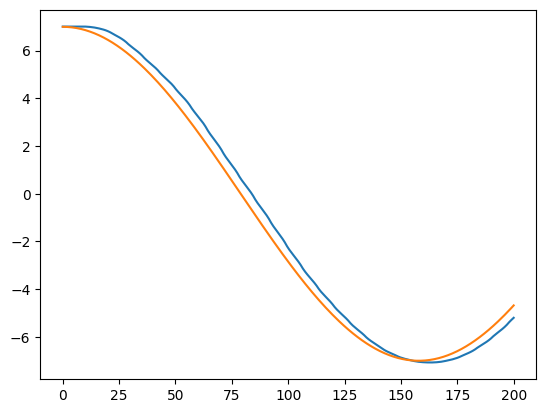

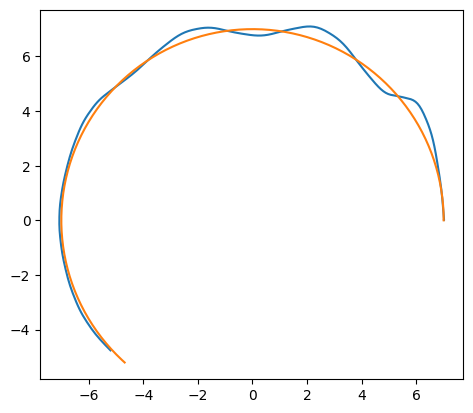

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import linalg
import copy
import math

class LIP:
    def __init__(self, m, g, h, dt, x0, xd0, y0, yd0, xleg0, yleg0):
        self.m = m
        self.g = g
        self.h = h
                
        self.dt = dt
        
        self.x = np.array([[x0],
                           [xd0],
                           [y0],
                           [yd0]])
        
        self.xleg = xleg0
        self.yleg = yleg0
        
        self.A = np.array([[0,          1, 0,          0],
                           [self.g / h, 0, 0,          0],
                           [0,          0, 0,          1],
                           [0,          0, self.g / h, 0]])
        
    def get_state(self):
        return self.x, self.xleg, self.yleg
    
    def propagate_system(self):
        xd = self.A @ (self.x - np.array([[self.xleg], [0], [self.yleg], [0]]))
        
        self.x += xd * self.dt
        
    def set_leg_position(self, newx, newy):
        self.xleg = newx
        self.yleg = newy
    
def run_LIP(m, g, h, x0, xd0, y0, yd0, dt, iter_num,
            step_time, ref_x, ref_y):
    lip = LIP(m, g, h, dt, x0, xd0, y0, yd0, x0, y0)

    x_traj = []
    y_traj = []
    x_leg_traj = []
    y_leg_traj = []
    
    t = 0
    time_elapsed = 0
    
    for i in range(iter_num):
        curr_t = dt * i
        
        state, xleg, yleg = lip.get_state()
                
        if (time_elapsed >= step_time):
            time_elapsed = 0
            
            #print(state[0, 0] - ref_x[i])
            
            # YOUR CODE BELOW
            
            newx = 
            newy = 

            # YOUR CODE ABOVE
            
            lip.set_leg_position(newx, newy)
            #print("new leg")
            
        x_traj.append(state[0, 0])
        y_traj.append(state[2, 0])
        x_leg_traj.append(xleg)
        y_leg_traj.append(yleg)
        
        lip.propagate_system()
        
        time_elapsed += dt
        #print(time_elapsed)
    
    return x_traj, y_traj, x_leg_traj, y_leg_traj

iter_num = 200
h = 2

# ref_x = [2 * np.cos(i / 7) for i in range(iter_num)]
# ref_y = [2 * np.sin(i / 7) for i in range(iter_num)]

ref_x, ref_y = [], []

for i in range(iter_num):
    angle1 = i / 50
    angle2 = i / 3.5
    
    x = np.cos(angle1) * 7 #(7 + 0.18 * np.cos(angle2))
    y = np.sin(angle1) * 7 #(7 + 0.18 * np.cos(angle2))
    
    ref_x.append(x)
    ref_y.append(y)

x_hist, y_hist, x_leg_traj, y_leg_traj = run_LIP(m = 1.0,
    g = 10, h = h, x0 = ref_x[0] + 0.01, xd0 = 0.004,
    y0 = ref_y[0] + 0.01, yd0 = -0.005,
    dt = 0.1, iter_num = iter_num, step_time = 0.7, ref_x = ref_x,
                                                 ref_y = ref_y)

print("simulation complete")

plt.plot(np.linspace(0, iter_num, iter_num), x_hist)
plt.plot(np.linspace(0, iter_num, iter_num), ref_x)
plt.show()

plt.plot(x_hist, y_hist)
plt.plot(ref_x, ref_y)
plt.gca().set_aspect('equal')
plt.show()

...субоптимальная визуализация...

In [5]:
import matplotlib.animation
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["animation.html"] = "jshtml"
plt.rcParams['figure.dpi'] = 150  
plt.ioff()

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

vis_step = 5

def draw_LIP(i):
    plt.cla()

    ax.plot([x_hist[i * vis_step], x_leg_traj[i * vis_step]],
            [y_hist[i * vis_step], y_leg_traj[i * vis_step]],
            [h, 0], 'bo-', label='lipm')
    
    ax.set_title("LIP walking")
    ax.set_xlabel("X (см)")
    ax.set_ylabel("Y (см)")
    ax.set_zlabel("Z (см)")
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)
    ax.set_zlim(0, 10)
    ax.legend(fontsize="x-large")
    ax.grid()

#xs = [1, 2, -3]

#for x1 in xs:
#    draw_LIP(x1)

#x = np.linspace(0,10,100)

matplotlib.animation.FuncAnimation(fig, draw_LIP, frames=40) #iter_num // vis_step)

### Задача 4

Закончите реализацию симуляции SLIP. Нужно будет дописать две функции.

1) *update_contact_status* для ноги. Почитайте код, поймите, что она должна делать
2) *propagate_system*. Это функция, где вычисляется правая часть уравнения динамики для SLIP

Для того, чтобы ходьба началась, после запуска программы нажмите любую клавишу.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import linalg
import copy
import math

class Leg:
    def __init__(self, l0, k, x0, in_contact = False):
        self.l0 = l0
        self.k = k
        self.x = x0
        self.in_contact = in_contact
    
    def calc_distance_to_point(self, x, y):
        return math.sqrt((x - self.x)**2 + y**2)
    
    def update_contact_status(self, x, y):
        d = self.calc_distance_to_point(x, y)

        # YOUR CODE BELOW
        
        
        
        # YOUR CODE ABOVE
            
    def draw(self, canvas, cx, cy, x, y, scale):
        leg_color = (23, 234, 21)

        if (self.in_contact == False):
            return
            leg_color = (123, 134, 21)

        cv2.line(canvas, (int(cx + x * scale), int(cy - y * scale)),
                         (int(cx + self.x * scale), cy), leg_color, 2)

class SLIP:
    def __init__(self, m = 1.0, g = 10.0,
                 x0 = 0.2, xd0 = -0.3, y0 = 1.2, yd0 = -0.1,
                 dt = 0.001, Q = np.eye(4), R = np.eye(1),
                 WIND_X = 700, scale = 100):
        self.m = m
        self.g = g
        
        self.x = np.array([[x0], [xd0], [y0], [yd0]])
        self.dt = dt
        
        self.Q = Q
        self.R = R
        
        self.WIND_X = WIND_X
        self.scale = scale
        self.target_x = 0.0
        
        self.legs = []
        
        self.walking_phase = "standing"
        
    def get_state(self):
        return self.x
    
    def add_leg(self, new_leg):
        self.legs.append(new_leg)
    
    def propagate_system(self, u):
        x  = self.x[0, 0]
        xd = self.x[1, 0]
        y  = self.x[2, 0]
        yd = self.x[3, 0]
        
        g = self.g
        m = self.m        
        
        xdd = 0
        ydd = 0

        # YOUR CODE BELOW

        # здесь нужно сделать следующее:
        # 1) пройти циклом по всем ногам
        # 2) если нога контактирует с поверхностью, обрабатываем ее
        # 3) в таком случае находим расстояние от центра масс до точки контакта
        # 4) находим силы
        # 5) находим вклад в ускорение по обеим осям
        # 6) не забываем учесть ускорение свободного падения
        
        

        # YOUR CODE BELOW
        
        self.x[1, 0] += xdd * self.dt
        self.x[0, 0] += self.x[1, 0] * self.dt
        
        self.x[3, 0] += ydd * self.dt
        self.x[2, 0] += self.x[3, 0] * self.dt
        
        for leg in self.legs:
            leg.update_contact_status(x, y)
        
        #if
        
    def draw(self, cx, cy, scale = 100, color = (234, 123, 123), canvas = None):
        if (canvas is None):
            canvas = np.ones((700, 700, 3)) * 0
        
        h, w, _ = canvas.shape

        cv2.line(canvas, (0, h // 2), (w, h // 2), color, 2)
        
        cv2.circle(canvas, (int(cx + self.x[0, 0] * scale), int(cy - self.x[2, 0] * scale)), 17, color, 2)

        for leg in self.legs:
            leg.draw(canvas, cx, cy, self.x[0, 0], self.x[2, 0], scale)

        return canvas
    
def state_action_cost(x, u, Q, R):
    cost = x.T @ Q @ x + u.T @ R @ u
    
    return cost

def episode_cost(x_hist, u_hist, Q, R):
    total_cost = 0
    cost_hist = []
    
    for x, u in zip(x_hist, u_hist):
        cost = state_action_cost(x, u, Q, R)
        
        total_cost += cost
        cost_hist.append(cost)
    
    return total_cost, cost_hist

def run_slip_episode(m = 1.0, g = 10.0,
                 x0 = 0.2, xd0 = -0.3, y0 = 1.2, yd0 = -0.1,
                 dt = 0.01, Q = np.eye(4), R = np.eye(1),
                 WIND_X = 700, scale = 100):
    WIND_X = 700
    WIND_Y = 700
    canvas = np.ones((700, 700, 3), np.uint8) * 70
    
    slip = SLIP(m, g, x0, xd0, y0, yd0,
                dt, Q, R, WIND_X, scale)

    x_first_leg = -0.99 - 5
    step = 1.6
    legs_num = 16

    for i in range(legs_num):
        new_leg = Leg(5, 100, x_first_leg + i * step, False)
        slip.add_leg(new_leg)
    
    iter_num = 2750
    i = 0

    x_traj = []
    y_traj = []
    u_traj = []
    
    Q = np.eye(4) * 1
    
    #Q[:2, :2] *= 10
    
    R = np.eye(1)
    
    horizon = 10

    F_max = 20
    
    updating = False
    
    while(True):
        state = slip.get_state()

        control = np.array([[0]])
        
        slip.propagate_system(control)
        
        x_traj.append(state[0, 0])
        y_traj.append(state[2, 0])
        u_traj.append(control)
        
        canvas = cv2.addWeighted(canvas, 0.93, canvas, 0, 0)
        slip.draw(WIND_X // 2, WIND_Y // 2, canvas = canvas, scale = scale)

        cv2.imshow("slip", canvas)
        
        if (updating == False):
            cv2.waitKey(0)
            updating = True
        
        i += 1

        if (i > iter_num):
            break
        
        key = cv2.waitKey(10) & 0xFF
        
        if (key == ord('q')):
            break
    
    cv2.destroyAllWindows()
    cv2.waitKey(10)
    
    return x_traj, y_traj

Q = np.eye(4)
Q[0, 0] *= 10
#Q[1, 1] *= 0.1
R = np.eye(1) * 1

x_hist, y_hist = run_slip_episode(m = 1.0, g = 10,
                 x0 = -5, xd0 = 1.3, y0 = 4.9, yd0 = 0.0,
                 dt = 0.01, Q = np.eye(4), R = np.eye(1),
                 WIND_X = 700, scale = 50)

def plot_1d(data):
    plt.figure(figsize=(15, 4))
    plt.plot(data)
    plt.show()

plot_1d(x_hist)
plot_1d(y_hist)

plt.figure(figsize=(15, 15))
plt.plot(x_hist, y_hist)
plt.show()